# 6 · Validation on held-out scans and the limit of the setup

So far the numbers on real data came from two scans (Corpo 5 and Corpo 6), the same ones on which I chose and tuned the algorithms: they are **development** errors, optimistic. However, the 33 scans contain all six solids for which I have the drawings. `data/scans.csv` lists the 14 that match a known solid; the two development ones are marked `dev`, the other 12 are `test` and guided no choice.

> [!NOTE]
> The solids in the scans were recognized automatically: for each scan the nominal profile with the minimum distance was chosen, keeping those with a median error below 1.6 mm and at least 150 points on the solid. The recognition is biased toward low errors, and the other 19 scans match none of the six profiles (probably Corpo 7, with the hole, or poses outside the measurement plane) and are not used. The solids are also FDM-printed, with an own tolerance of the order of 0.2-0.3 mm.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.calibration import distort_points, project
from lightsheet3d.dataset import Dataset
from lightsheet3d.evaluate import evaluate, summarize
from lightsheet3d.laser import laser_centroids
from lightsheet3d.scanner import Calibration, Scanner
from lightsheet3d.solids import SOLIDS, nominal_curve

dataset = Dataset.load(ROOT / "data" / "dataset.toml")
calibration = Calibration.fit(dataset)
results = evaluate(calibration, dataset)
for by in ("role", "solid"):
    print(f"by {by}:")
    for key, s in summarize(results, by).items():
        print(f"  {key:7s} {s['scans']:2d} scans  median distance (mean) {s['median']:.2f} mm, worst {s['worst']:.2f} mm  |  peak heights: mean error {s['height_mean']:+.2f} mm, rms {s['height_rms']:.2f} mm")

by role:
  dev      2 scans  median distance (mean) 0.58 mm, worst 0.62 mm  |  peak heights: mean error -0.33 mm, rms 0.58 mm
  test    12 scans  median distance (mean) 0.91 mm, worst 1.54 mm  |  peak heights: mean error -0.15 mm, rms 0.75 mm
by solid:
  corpo1   2 scans  median distance (mean) 1.34 mm, worst 1.54 mm  |  peak heights: mean error +nan mm, rms nan mm
  corpo2   2 scans  median distance (mean) 0.67 mm, worst 0.91 mm  |  peak heights: mean error -0.35 mm, rms 0.35 mm
  corpo3   4 scans  median distance (mean) 0.66 mm, worst 0.79 mm  |  peak heights: mean error -0.31 mm, rms 0.87 mm
  corpo4   2 scans  median distance (mean) 1.01 mm, worst 1.33 mm  |  peak heights: mean error +0.07 mm, rms 0.68 mm
  corpo5   2 scans  median distance (mean) 0.90 mm, worst 1.17 mm  |  peak heights: mean error +0.03 mm, rms 0.33 mm
  corpo6   2 scans  median distance (mean) 0.81 mm, worst 1.07 mm  |  peak heights: mean error -0.30 mm, rms 0.72 mm


## Error per scan, with and without oblique stretching

With `oblique=True` the nominal profile may stretch along Y: this is needed when the solid is placed across the sheet, because the cut is oblique and the measured profile turns out stretched by 1/cos(angle). The scale found is a positioning parameter and is always reported: for well-aligned scans it must come out as 1.00, and it is an independent check of the Y scale of the calibration.

scan       solid   role    median  oblique      stretch         tilt
30o3       corpo5  dev       0.62     0.61         1.02         11°
30o34      corpo6  dev       0.55     0.55         1.00          0°
30o5       corpo5  test      1.17     1.31         1.15         30°
30o37      corpo6  test      1.07     0.94         1.10         25°
30o30      corpo3  test      0.79     0.79         1.00          0°
30o31      corpo3  test      0.48     0.48         1.00          0°
30o32      corpo3  test      0.74     0.43         1.07         21°
30o33      corpo3  test      0.63     0.63         1.00          0°
30o7       corpo2  test      0.44     0.44         1.00          0°
30o8       corpo2  test      0.91     0.76         1.18         32°
30o11      corpo4  test      1.33     0.89         1.33         41°
30o12      corpo4  test      0.70     0.70         1.00          0°
30o14      corpo1  test      1.14     1.14         1.00          0°
30o15      corpo1  test      1.54     1.00     

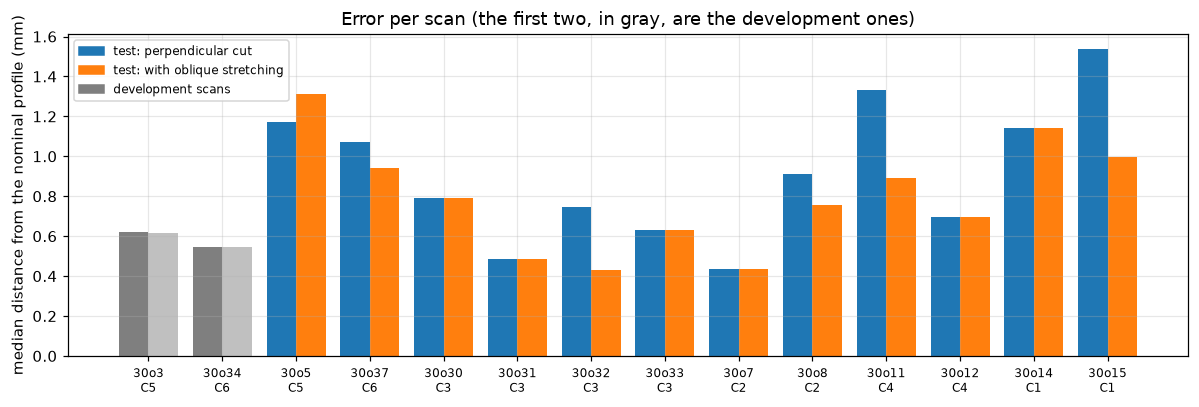

In [2]:
oblique = evaluate(calibration, dataset, oblique=True)
print(f"{'scan':10s} {'solid':7s} {'role':5s} {'median':>8s} {'oblique':>8s} {'stretch':>12s} {'tilt':>12s}")
for a, b in zip(results, oblique):
    tilt = np.degrees(np.arccos(min(1, 1 / b.scale)))
    print(f"{a.file[:-4]:10s} {a.solid:7s} {a.role:5s} {a.median:8.2f} {b.median:8.2f} {b.scale:12.2f} {tilt:10.0f}°")
test = [(a.median, b.median, b.scale) for a, b in zip(results, oblique) if a.role == "test"]
print(f"test: mean median {np.mean([t[0] for t in test]):.2f} mm -> {np.mean([t[1] for t in test]):.2f} mm with stretching")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(results))
ax.bar(x - 0.2, [r.median for r in results], 0.4, color=["tab:gray" if r.role == "dev" else "tab:blue" for r in results], label="perpendicular cut")
ax.bar(x + 0.2, [r.median for r in oblique], 0.4, color=["silver" if r.role == "dev" else "tab:orange" for r in results], label="with oblique stretching")
ax.set_xticks(x, [f"{r.file[:-4]}\n{r.solid.replace('corpo', 'C')}" for r in results], fontsize=8)
ax.set(ylabel="median distance from the nominal profile (mm)", title="Error per scan (the first two, in gray, are the development ones)")
from matplotlib.patches import Patch

ax.legend(handles=[Patch(color="tab:blue", label="test: perpendicular cut"), Patch(color="tab:orange", label="test: with oblique stretching"),
                   Patch(color="tab:gray", label="development scans")], loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "heldout_scans.png", bbox_inches="tight")

## One profile per solid

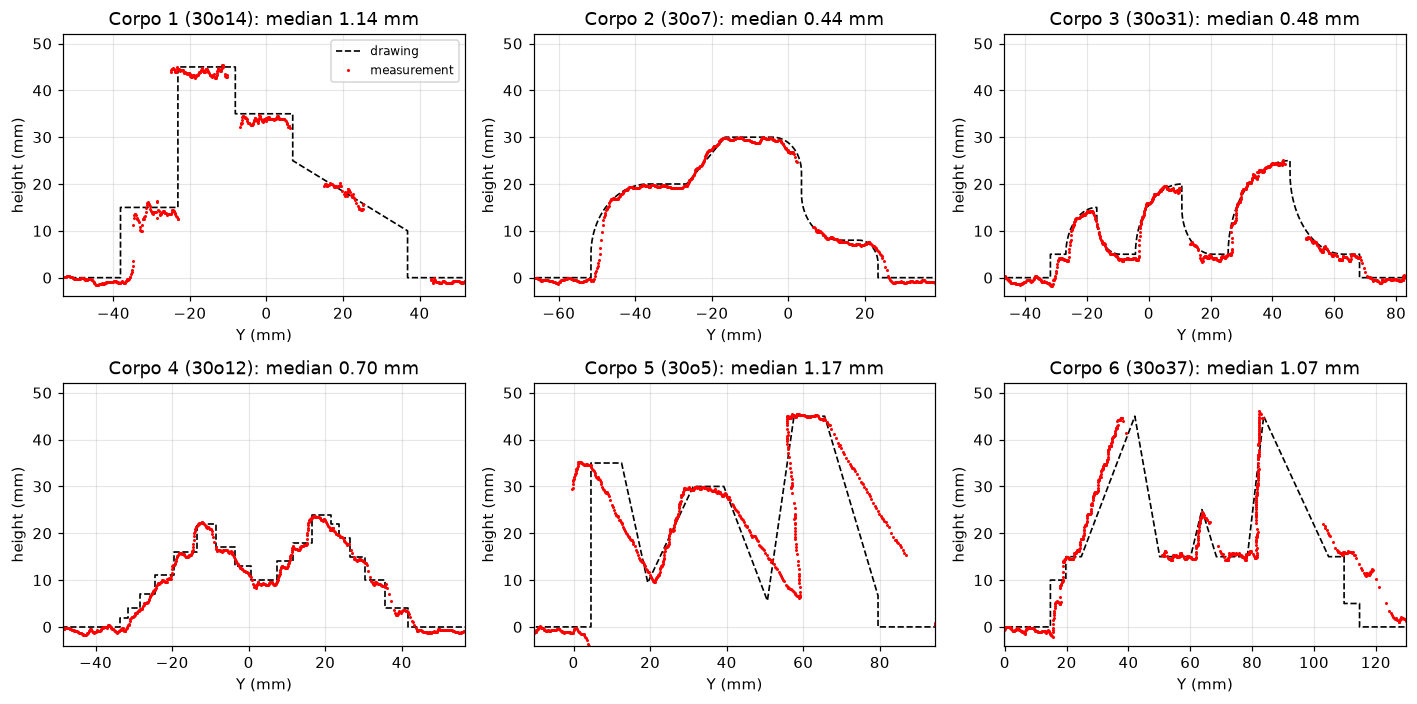

In [3]:
PICK = {"corpo1": "30o14.jpg", "corpo2": "30o7.jpg", "corpo3": "30o31.jpg", "corpo4": "30o12.jpg", "corpo5": "30o5.jpg", "corpo6": "30o37.jpg"}
scanner = Scanner(calibration)
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (key, name) in zip(axs.ravel(), PICK.items()):
    profile, solid = scanner.scan(dataset.scans_path / name), SOLIDS[key]
    comparison = profile.compare(solid)
    yn, hn = nominal_curve(solid, comparison.sign, comparison.shift, pad=40)
    ax.plot(yn, hn, "k--", lw=1.1, label="drawing")
    ax.plot(profile.y, profile.height, "r.", ms=2, label="measurement")
    span = (comparison.sign * solid.outline[:, 0] + comparison.shift)
    ax.set(xlim=(span.min() - 15, span.max() + 15), ylim=(-4, 52), title=f"{solid.name} ({name[:-4]}): median {comparison.median:.2f} mm")
    ax.set_xlabel("Y (mm)"); ax.set_ylabel("height (mm)")
axs[0, 0].legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "heldout_profiles.png", bbox_inches="tight")

## The limit of the setup

Three measurements, all on real data, explain why the error does not drop below about 0.5-1 mm.

1. Sensitivity: the sheet moves by 0.79 px per mm of height: one pixel of error on the sheet is worth 1.27 mm of height.


2. The line on the support plane is shifted by -0.82 px on average relative to the calibration, from -1.75 to -0.04 px across the scans.
3. The median error on the test scans (0.91 mm) corresponds to 0.72 px on the sheet.


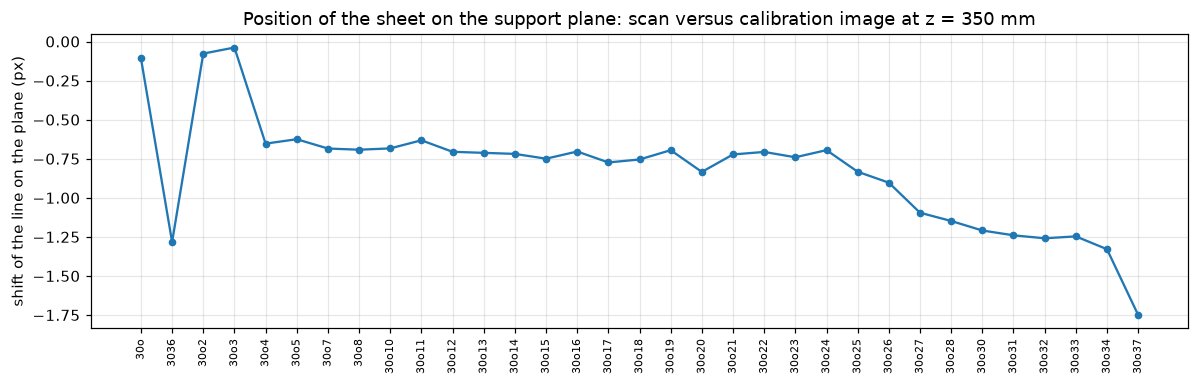

In [4]:
P, (A, B, C), center, k = calibration.model.P, calibration.plane, calibration.model.center, calibration.model.k

def pixel(z, y=0.0):
    x = (z - B * y - C) / A  # sheet point at height z
    return distort_points(project(P, np.array([[x, y, z]])), center, k)[0]

per_mm = abs(pixel(300)[0] - pixel(350)[0]) / 50
print(f"1. Sensitivity: the sheet moves by {per_mm:.2f} px per mm of height: one pixel of error on the sheet is worth {1 / per_mm:.2f} mm of height.")

# 2. the sheet line on the support plane in the scans, against the same line in the calibration image at z = 350
ref = laser_centroids(cv.imread(str(dataset.sheet_path / "30l.jpg")))
ref_u = dict(zip(ref[:, 1].round().astype(int), ref[:, 0]))
files = sorted((f for f in dataset.scans_path.glob("*.jpg")), key=lambda f: (len(f.stem), f.stem))
shifts = []
for f in files:
    uv = laser_centroids(cv.imread(str(f)))
    d = [u - ref_u[round(v)] for u, v in uv if (v < 250 or v > 1150) and round(v) in ref_u]
    shifts.append(np.median(d) if len(d) > 50 else np.nan)
print(f"2. The line on the support plane is shifted by {np.nanmean(shifts):+.2f} px on average relative to the calibration, from {np.nanmin(shifts):+.2f} to {np.nanmax(shifts):+.2f} px across the scans.")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(range(len(files)), shifts, "o-", ms=4)
ax.set_xticks(range(len(files)), [f.stem for f in files], rotation=90, fontsize=7)
ax.set(ylabel="shift of the line on the plane (px)", title="Position of the sheet on the support plane: scan versus calibration image at z = 350 mm")
fig.tight_layout(); fig.savefig(FIGURES / "plate_line_drift.png", bbox_inches="tight")

median_px = float(np.mean([r.median for r in results if r.role == "test"])) * per_mm
print(f"3. The median error on the test scans ({np.mean([r.median for r in results if r.role == 'test']):.2f} mm) corresponds to {median_px:.2f} px on the sheet.")

* **The honest number is 0.9 mm, not 0.55.** On the 12 test scans, of solids that no choice has ever seen, the mean median error is 0.91 mm (worst 1.54 mm). The 0.55 and 0.62 mm of the previous notebooks were development figures.
* **The setup has a low sensitivity.** 0.79 px per mm of height: one pixel of error is 1.27 mm. The error on the tests corresponds to about 0.7 px, so we are close to what the triangulation geometry allows with this laser and this camera; it is not a limit of the code.
* **The bench moved during the acquisition.** The line on the support plane starts close to the calibration in the first scans and drifts progressively to over 1 px (about 1.5 mm) in the last ones. The per-scan leveling removes a pure shift, but it shows that camera, laser or plane were not still.
* **Scans placed across the sheet weigh on the error.** With oblique stretching the median error on the test set drops from 0.91 to about 0.79 mm. Where the solid is aligned with the sheet the scale is 1.00, so the Y scale of the calibration (20 mm pitch) is correct within about 1%; where it comes out 1.07-1.33 the solid is tilted by 20-40 degrees. In one case (30o5) it gets worse: the pose is more complex than a rotation.\n* **What does not change the result.** Removing the inconsistent calibration views (330, 340) or correcting the height of each view improves the camera fit but not the error on the tests.